## Exercise 10 - Decision tree

- Use the same dataset as in previous exercises (voice.csv)
- Dataset includes male and female voice samples with different features
- In this exercise you will use supervised machine learning method called decision tree for the dataset
- **The goal of this exercise is to distinguish male and female voices from the given data**

1 Import all necessary libraries. Then load the dataset and save it to the dataframe. Filter dataframe for meanfun and IQR columns only.

In [17]:
import pandas as pd
from sklearn import metrics, tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("data_files/voice.csv", delimiter=",")
voice_data = pd.DataFrame(data)

X = voice_data[["meanfun", "IQR"]]
y = voice_data["label"]

2 Divide the data with the following portions:
   - Training data 70 %
   - Test data 30 %

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.70, random_state=42)

3 Define classifier without the max_depth parameter. Use get_depth() method for the defined classifier. What value for tree depth was chosen automatically?

In [19]:
clf_unlimited = DecisionTreeClassifier(random_state=42)
clf_unlimited.fit(X_train, y_train)

auto_depth = clf_unlimited.get_depth()
print(f"The tree depth chosen automatically was: {auto_depth}\n")

The tree depth chosen automatically was: 15



4 Visualise the tree structure and create the confusion matrix where you can compare true and predicted labels.

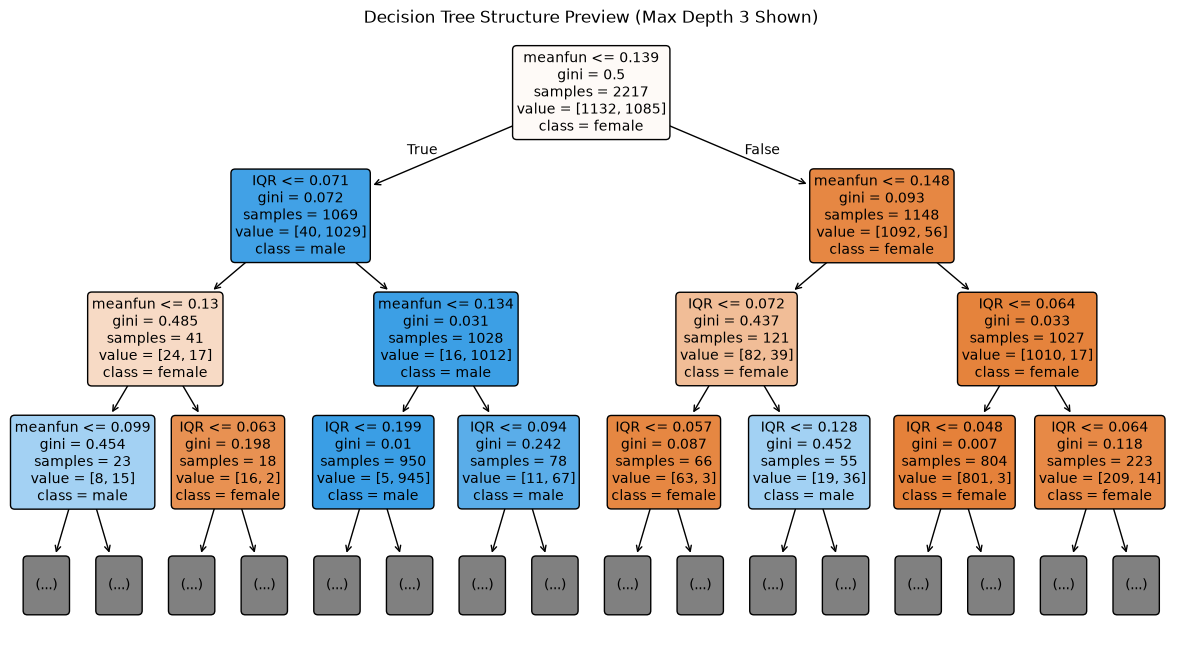

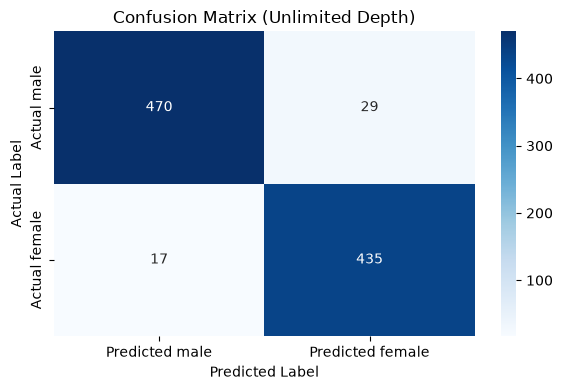

In [20]:
# Tree structure 
plt.figure(figsize=(15, 8))
tree.plot_tree(
    clf_unlimited, 
    max_depth=3, 
    feature_names=X.columns, 
    class_names=clf_unlimited.classes_, 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure Preview (Max Depth 3 Shown)")
plt.show()

# Confusion Matrix
y_pred_unlimited = clf_unlimited.predict(X_test)
unique_labels = voice_data["label"].unique()
cm = metrics.confusion_matrix(y_test, y_pred_unlimited, labels=unique_labels)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=[f"Predicted {l}" for l in unique_labels], 
    yticklabels=[f"Actual {l}" for l in unique_labels]
)
plt.title("Confusion Matrix (Unlimited Depth)")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()

5 Create a function which provides the accuracy score for maximum tree depths ranging from 1 to 20. The following operations should be done in order within the function:
- Define a classifier with given maximum tree depth
- Train the classifier model with previously defined training data and labels (x_train and y_train)
- Create predictions with the test data (x_test) and store results to y_pred variable
- Calculate the accuracy score using **metrics.accuracy_score(y_test, y_pred)**

What maximum tree depth value gives the best accuracy score?

--- ITERATIONS ---
Max Depth:  1 | Accuracy: 0.9443
Max Depth:  2 | Accuracy: 0.9432
Max Depth:  3 | Accuracy: 0.9685
Max Depth:  4 | Accuracy: 0.9664
Max Depth:  5 | Accuracy: 0.9611
Max Depth:  6 | Accuracy: 0.9590
Max Depth:  7 | Accuracy: 0.9548
Max Depth:  8 | Accuracy: 0.9537
Max Depth:  9 | Accuracy: 0.9548
Max Depth: 10 | Accuracy: 0.9527
Max Depth: 11 | Accuracy: 0.9527
Max Depth: 12 | Accuracy: 0.9527
Max Depth: 13 | Accuracy: 0.9527
Max Depth: 14 | Accuracy: 0.9527
Max Depth: 15 | Accuracy: 0.9516
Max Depth: 16 | Accuracy: 0.9516
Max Depth: 17 | Accuracy: 0.9516
Max Depth: 18 | Accuracy: 0.9516
Max Depth: 19 | Accuracy: 0.9516
Max Depth: 20 | Accuracy: 0.9516


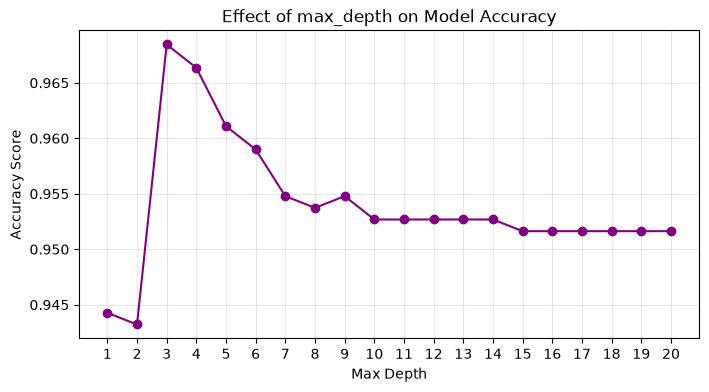


--- FINAL CONCLUSION ---
The maximum tree depth value that gives the best accuracy score is: 3 (Accuracy: 96.85%)


In [21]:
def evaluate_tree_depths(X_tr, X_te, y_tr, y_te):
    depths = range(1, 21)
    accuracies = []
    
    print("--- ITERATIONS ---")
    for depth in depths:
        # - Define a classifier with given maximum tree depth
        clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
        
        # - Train the classifier model
        clf.fit(X_tr, y_tr)
        
        # - Create predictions with the test data and store results to y_pred
        y_pred = clf.predict(X_te)
        
        # - Calculate the accuracy score using metrics.accuracy_score
        acc = metrics.accuracy_score(y_te, y_pred)
        accuracies.append(acc)
        print(f"Max Depth: {depth:2d} | Accuracy: {acc:.4f}")
    
    # Plot accuracy vs depth for visual evaluation
    plt.figure(figsize=(8, 4))
    plt.plot(depths, accuracies, marker='o', color='purple')
    plt.title("Effect of max_depth on Model Accuracy")
    plt.xlabel("Max Depth")
    plt.ylabel("Accuracy Score")
    plt.xticks(depths)
    plt.grid(True, alpha=0.3)
    plt.show()

    # Find the depth that gives the best accuracy score
    best_acc = max(accuracies)
    best_depth = depths[accuracies.index(best_acc)]
    
    print("\n--- FINAL CONCLUSION ---")
    print(f"The maximum tree depth value that gives the best accuracy score is: {best_depth} (Accuracy: {best_acc:.2%})")

evaluate_tree_depths(X_train, X_test, y_train, y_test)